<a href="https://colab.research.google.com/github/sofia-crisafulli/pill-faers-signal-detection/blob/main/notebooks/01_pill_faers_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 – FAERS signal detection for oral contraceptives
Authors: Sofia Crisafulli and Emily Campanelli

Data accessed: 17 November 2026, via the openFDA drug adverse event API (FAERS).
The FDA updates the data regularly, so re-running the notebook can change some counts slightly. The numbers in the text come from our runs in November 2026; small differences from the printed outputs do not affect any result.

**Project question:** do oral contraceptives with different progestins show different adverse event reporting patterns (thromboembolism, mood, migraine), and does it change with age?

## Step 1 – First access test (levonorgestrel, female patients)

We queried the API for reports mentioning levonorgestrel in female patients.



In [1]:
import os
import requests

# Read the API key
try:
    from google.colab import userdata
    API_KEY = userdata.get("OPENFDA_API_KEY")
except ImportError:
    API_KEY = os.environ.get("OPENFDA_API_KEY")

URL = "https://api.fda.gov/drug/event.json"

# Reports mentioning levonorgestrel, female patients (patientsex = 2)
search = 'patient.drug.openfda.substance_name:"LEVONORGESTREL" AND patient.patientsex:2'

# 1) Total number of matching reports
r = requests.get(URL, params={"search": search, "limit": 1, "api_key": API_KEY})
print("Status:", r.status_code)
if r.status_code != 200:
    print("Error message:", r.text[:300])
else:
    print("Total reports:", r.json()["meta"]["results"]["total"])

    # 2) The 20 most frequent reaction terms
    r = requests.get(URL, params={
        "search": search,
        "count": "patient.reaction.reactionmeddrapt.exact",
        "limit": 20,
        "api_key": API_KEY,
    })
    print("Status:", r.status_code)
    for row in r.json()["results"]:
        print(f'{row["term"]:<40} {row["count"]}')

Status: 200
Total reports: 202031
Status: 200
DEVICE EXPULSION                         45662
DEVICE DISLOCATION                       20651
MENSTRUATION IRREGULAR                   15010
VAGINAL HAEMORRHAGE                      15006
GENITAL HAEMORRHAGE                      11247
ABDOMINAL PAIN LOWER                     9355
ABDOMINAL PAIN                           8587
NAUSEA                                   8570
PROCEDURAL PAIN                          8505
PAIN                                     7541
UTERINE PERFORATION                      7445
DRUG INEFFECTIVE                         7368
PELVIC PAIN                              6867
HEADACHE                                 6509
PREGNANCY WITH CONTRACEPTIVE DEVICE      5955
MENSTRUATION DELAYED                     5762
COMPLICATION OF DEVICE INSERTION         5761
INTRA-UTERINE CONTRACEPTIVE DEVICE EXPELLED 5569
FATIGUE                                  5268
DYSMENORRHOEA                            5049


**Results:** 202,030 reports. The most frequent reaction terms are *device expulsion* (45,661), *device dislocation* (20,652) and *uterine perforation*, which are events of intrauterine devices (IUDs), not of the pill.

**Takeaway:** filtering by active substance alone mixes very different products, so we need to restrict to oral products.

## Step 2 – Filtering by route of administration

We checked which routes of administration appear in the reports. We then kept only oral products and excluded reports that also mention an intrauterine product, to avoid reports related to intrauterine devices (IUDs).

We then listed the 20 most frequent reactions to check whether they are typical of the pill.

In [2]:
def count_reports(search):
    r = requests.get(URL, params={"search": search, "limit": 1, "api_key": API_KEY})
    if r.status_code != 200:
        return r.status_code, r.text[:300]
    return r.status_code, r.json()["meta"]["results"]["total"]

def top_terms(search, field, n=20):
    r = requests.get(URL, params={"search": search, "count": field, "limit": n, "api_key": API_KEY})
    if r.status_code != 200:
        return r.status_code, r.text[:300]
    return r.status_code, [(x["term"], x["count"]) for x in r.json()["results"]]

base = 'patient.drug.openfda.substance_name:"LEVONORGESTREL" AND patient.patientsex:2'

# 1) Which administration routes appear in these reports?
status, routes = top_terms(base, "patient.drug.openfda.route.exact", 10)
print("Routes found:", status)
print(routes)

# 2) Oral products only and not intrauterine
oral = base + ' AND patient.drug.openfda.route:"ORAL" AND NOT patient.drug.openfda.route:"INTRAUTERINE"'
status, total = count_reports(oral)
print("\nOral levonorgestrel reports:", status, total)

# 3) Top 20 reaction terms for the oral subset
status, terms = top_terms(oral, "patient.reaction.reactionmeddrapt.exact", 20)
print("Top terms:", status)
if status == 200:
    for term, count in terms:
        print(f"{term:<40} {count}")
else:
    print(terms)

Routes found: 200
[('INTRAUTERINE', 159672), ('ORAL', 53907), ('INTRAVENOUS', 6121), ('TRANSDERMAL', 3862), ('SUBCUTANEOUS', 3679), ('TOPICAL', 3481), ('INTRAMUSCULAR', 3006), ('NASAL', 1643), ('RESPIRATORY (INHALATION)', 1591), ('RECTAL', 1250)]

Oral levonorgestrel reports: 200 39745
Top terms: 200
MENSTRUATION IRREGULAR                   13634
VAGINAL HAEMORRHAGE                      7727
MENSTRUATION DELAYED                     4874
NAUSEA                                   4872
DYSMENORRHOEA                            3913
VOMITING                                 3253
HEADACHE                                 2255
PELVIC PAIN                              2240
FATIGUE                                  2006
PREGNANCY AFTER POST COITAL CONTRACEPTION 1919
DIZZINESS                                1817
BREAST TENDERNESS                        1642
VAGINAL DISCHARGE                        1632
ABDOMINAL PAIN                           1582
DRUG INEFFECTIVE                         1487
INTENT

**Results:** Among reports mentioning levonorgestrel in women, 159,673 involve intrauterine products and 53,907 involve oral products. After keeping only oral products and excluding reports that also mention an intrauterine product, 39,742 reports remain. The most frequent reactions are now irregular menstruation, vaginal haemorrhage, menstruation delayed, nausea and headache, which are typical of the pill.

**Takeaway:** Filtering by route removed the IUD events, which were about 79% of the reports. However, the oral group still includes emergency contraception: the term "pregnancy after post coital contraception" appears 1,920 times. We need to remove it in the next step.

## Step 3 – Combined oral pills and denominators

The daily pill is combined: it contains a progestin (for example levonorgestrel) and an estrogen (ethinyl estradiol). Emergency contraception contains only levonorgestrel.

We therefore searched for reports that mention levonorgestrel and ethinyl estradiol together, in order to exclude emergency contraception.

We also counted all reports in women and all reports in total, which we need as denominators for the next analysis.

In [3]:
PROGESTINS = ["LEVONORGESTREL", "DROSPIRENONE", "DESOGESTREL", "NORGESTIMATE"]

def combined_pill_query(progestin):
    return (
        f'patient.drug.openfda.substance_name:"{progestin}"'
        ' AND patient.drug.openfda.substance_name:"ETHINYL ESTRADIOL"'
        ' AND patient.drug.openfda.route:"ORAL"'
        ' AND NOT patient.drug.openfda.route:"INTRAUTERINE"'
        ' AND patient.patientsex:2'
    )

print("== Combined oral pills, female patients ==")
for p in PROGESTINS:
    q = combined_pill_query(p)
    status, total = count_reports(q)
    status_age, with_age = count_reports(q + " AND patient.patientonsetage:[10 TO 60]")
    print(f"{p:<16} total: {total}   with age 10-60: {with_age}")

print("\n== Denominators ==")
print("All female reports:", count_reports("patient.patientsex:2"))
print("All reports:", count_reports("receivedate:[20040101 TO 20261231]"))

== Combined oral pills, female patients ==
LEVONORGESTREL   total: 738   with age 10-60: 511
DROSPIRENONE     total: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}   with age 10-60: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}
DESOGESTREL      total: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}   with age 10-60: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}
NORGESTIMATE     total: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}   with age 10-60: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}

== Denominators ==
All female reports: (200, 11092365)
All reports: (200, 21053772)


**Results:** Levonorgestrel + ethinyl estradiol (oral) returns 736 reports, 511 of them with age between 10 and 60. Drospirenone, desogestrel and norgestimate return no matches.
Denominators: 11,092,411 reports in female patients and 21,053,772 reports in total.

**Takeaway:** The filter works for levonorgestrel, but it returns very few reports (736) and finds nothing for drospirenone, desogestrel and norgestimate. This does not mean that these pills have no reports, but that our filter does not capture them.

We need to find a better way to identify the pills.

## Step 4 – Why the filter failed

The filter in Step 3 found almost nothing for drospirenone, desogestrel and norgestimate. We suspected that the standardised "openfda" fields do not cover every product name, because this information is only added when the reported drug name is matched to a registered product.

To check this, we ran two tests. First, for each progestin we looked at how many reports there were, which routes of administration appeared and which other substances appeared together.

Second, we searched the field "medicinalproduct", which contains the drug name exactly as it was written by the reporter, using a list of brand names.

In [4]:
def n(query):
    """Return the number of matching reports (0 if none)."""
    status, total = count_reports(query)
    return total if status == 200 else 0

# 1) How do these active substances appear in the data?
for p in ["DROSPIRENONE", "DESOGESTREL", "NORGESTIMATE", "LEVONORGESTREL"]:
    s = f'patient.drug.openfda.substance_name:"{p}" AND patient.patientsex:2'
    print(f"\n{p}: reports with this substance =", n(s))
    print("  routes:", top_terms(s, "patient.drug.openfda.route.exact", 5)[1])
    print("  substances:", top_terms(s, "patient.drug.openfda.substance_name.exact", 8)[1])

# 2) Reports by brand name as written by the reporter
BRANDS = {
    "DROSPIRENONE":  ["YAZ", "YASMIN", "BEYAZ", "SAFYRAL", "OCELLA", "GIANVI"],
    "DESOGESTREL":   ["DESOGEN", "MIRCETTE", "CYCLESSA", "APRI", "KARIVA"],
    "NORGESTIMATE":  ["ORTHO TRI-CYCLEN", "ORTHO-CYCLEN", "SPRINTEC", "TRI-SPRINTEC"],
}
print("\n== Reports by brand name (reported text) ==")
for substance, brands in BRANDS.items():
    for b in brands:
        q = f'patient.drug.medicinalproduct:"{b}" AND patient.patientsex:2'
        print(f"{substance:<14} {b:<18} {n(q)}")


DROSPIRENONE: reports with this substance = 521
  routes: [('ORAL', 521), ('INTRAVENOUS', 100), ('SUBCUTANEOUS', 66), ('INTRAMUSCULAR', 60), ('TOPICAL', 48)]
  substances: [('DROSPIRENONE', 521), ('ESTRADIOL', 521), ('ACETAMINOPHEN', 25), ('OMEPRAZOLE MAGNESIUM', 24), ('SODIUM BICARBONATE', 24), ('OMEPRAZOLE', 23), ('NIACINAMIDE', 22), ('ERGOCALCIFEROL', 21)]

DESOGESTREL: reports with this substance = 0
  routes: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}
  substances: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}

NORGESTIMATE: reports with this substance = 0
  routes: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}
  substances: {
  "error": {
    "code": "NOT_FOUND",
    "message": "No matches found!"
  }
}

LEVONORGESTREL: reports with this substance = 202031
  routes: [('INTRAUTERINE', 159672), ('ORAL', 53907), ('INTRAVENOUS', 6121), ('TRANSDERMAL', 3862), ('SUBCUTANEOUS', 3

**Results:**
- With the standardised "openfda" fields, drospirenone appears in only 521 reports, and all of them also mention estradiol (not ethinyl estradiol), so they refer to a different, hormone-replacement product. Desogestrel and norgestimate return no reports at all.
- Searching by brand name as written by the reporter gives much larger numbers, for example YAZ (29,171 reports), YASMIN (23,236) and ORTHO TRI-CYCLEN (6,295).

**Takeaway:** The standardised fields miss most of the pill reports, which supports our hypothesis that many brand names are not matched to a registered product. Therefore, we define each pill group by a list of brand names. This approach has limitations: the field is free text, so spelling variants may be missed; one report can mention several brands; a brand can appear as a concomitant drug and not as the suspected one; and the high counts for YAZ and YASMIN may partly reflect litigation-driven reporting, which we will examine by reporting year.

## Step 5 – Pill groups by brand name

We now define each pill group
with a list of brand names, searched in the field "medicinalproduct". For each progestin (drospirenone, desogestrel, norgestimate and levonorgestrel in combined pills) we combine
its brand names with OR, so that a report is counted once even if it mentions several
brands. We keep only female patients.

Then we count the reports in each group, and how many of them also have a valid age between 10 and 60, which we will need for the age analysis later.

In [5]:
GROUPS = {
    "drospirenone":            ["YAZ", "YASMIN", "BEYAZ", "SAFYRAL", "OCELLA", "GIANVI"],
    "desogestrel":             ["DESOGEN", "MIRCETTE", "CYCLESSA", "APRI", "KARIVA"],
    "norgestimate":            ["ORTHO TRI-CYCLEN", "ORTHO-CYCLEN", "SPRINTEC", "TRI-SPRINTEC"],
    "levonorgestrel_combined": ["SEASONIQUE", "SEASONALE", "LYBREL", "ALESSE", "NORDETTE",
                                "TRIVORA", "LEVLEN", "LESSINA", "AVIANE", "LUTERA",
                                "PORTIA", "AMETHYST", "JOLESSA"],
}

def group_query(brands):
    names = " OR ".join(f'patient.drug.medicinalproduct:"{b}"' for b in brands)
    return f"({names}) AND patient.patientsex:2"

print("Reports per pill group (brand names, female patients)")
for group, brands in GROUPS.items():
    q = group_query(brands)
    with_age = n(q + " AND patient.patientonsetage:[10 TO 60]")
    print(f"{group:<26} total: {n(q):>7}   age 10-60: {with_age:>7}")

Reports per pill group (brand names, female patients)
drospirenone               total:   45409   age 10-60:   32017
desogestrel                total:    1514   age 10-60:     973
norgestimate               total:    9923   age 10-60:    5677
levonorgestrel_combined    total:    4786   age 10-60:    3208


**Results:**
- Drospirenone is by far the largest group, with 45,410 reports (32,020 with age between 10 and 60).
- The other groups are much smaller: norgestimate 9,924 (5,679), levonorgestrel 4,784 (3,208) and desogestrel 1,515 (974).
- For drospirenone, the sum of the individual brand counts is around 60,800, which is larger than the group total.
- A valid age (10-60) is reported in 57-70% of the reports, depending on the group.

**Takeaway:** The groups turn out to be very unbalanced: drospirenone has about 30 times more reports
than desogestrel. The sum of the brand counts is larger than the group total because many
reports mention more than one brand, and the OR query counts each report only once, so we use the group totals. Desogestrel is the smallest
group, so its results will be less precise, especially when we split them by age. Age is missing or outside the range in 30-43% of the reports, so the age analysis will use only a part of the data.

## Step 6 – Disproportionality analysis (PRR and ROR)

In this step, we test whether each event is reported more often with a certain pill in comparison to every other drug taken by women.

We look at four groups of events: thromboembolism, mood, migraine and generic headache, which we keep as a comparison for migraine. Thromboembolism is the positive control: it is a known risk of combined pills, so if the method works, it should show up as a signal.

For each pill and event we build a 2x2 table and compute the Proportional Reporting Ratio (PRR) and the Reporting Odds Ratio (ROR), with a 95% confidence interval. There is a signal if there are at least 3 cases, the PRR is at least 2 and the lower bound of the ROR interval is above 1.

A signal does not prove that the pill causes the event. Also, how often an event is reported does not measure the actual risk.

In [6]:
import math
import pandas as pd

EVENTS = {
    "thromboembolism": ["DEEP VEIN THROMBOSIS", "PULMONARY EMBOLISM", "THROMBOSIS", "VENOUS THROMBOSIS"],
    "mood":            ["DEPRESSION", "DEPRESSED MOOD", "ANXIETY", "MOOD SWINGS",
                        "SUICIDAL IDEATION", "IRRITABILITY", "AFFECT LABILITY"],
    "migraine":        ["MIGRAINE", "MIGRAINE WITH AURA", "AURA"],
    "headache":        ["HEADACHE"],
}

def event_query(terms):
    names = " OR ".join(f'patient.reaction.reactionmeddrapt.exact:"{t}"' for t in terms)
    return f"({names})"

# 1) Check that each term exists in the data (female patients)
print("== Reports per reaction term (all drugs, female patients) ==")
for ev, terms in EVENTS.items():
    for t in terms:
        q = f'patient.reaction.reactionmeddrapt.exact:"{t}" AND patient.patientsex:2'
        print(f"{ev:<16} {t:<24} {n(q)}")

# 2) Disproportionality: PRR and ROR with 95% CI
N = n("patient.patientsex:2")          # all female reports
rows = []
for ev, terms in EVENTS.items():
    eq = event_query(terms)
    ac = n(eq + " AND patient.patientsex:2")   # event reports, all drugs
    for g, brands in GROUPS.items():
        gq = group_query(brands)
        ab = n(gq)                              # group reports
        a  = n(gq + " AND " + eq)               # group reports with the event
        b, c = ab - a, ac - a
        d = N - ab - c
        if min(a, b, c, d) <= 0:
            rows.append({"event": ev, "group": g, "a": a, "PRR": None, "ROR": None})
            continue
        prr = (a / (a + b)) / (c / (c + d))
        ror = (a * d) / (b * c)
        se = math.sqrt(1/a + 1/b + 1/c + 1/d)
        rows.append({
            "event": ev, "group": g, "reports": ab, "a": a,
            "PRR": round(prr, 2), "ROR": round(ror, 2),
            "ROR_lo": round(math.exp(math.log(ror) - 1.96*se), 2),
            "ROR_hi": round(math.exp(math.log(ror) + 1.96*se), 2),
        })

results = pd.DataFrame(rows)
results["signal"] = (results["a"] >= 3) & (results["PRR"] >= 2) & (results["ROR_lo"] > 1)
results

== Reports per reaction term (all drugs, female patients) ==
thromboembolism  DEEP VEIN THROMBOSIS     35860
thromboembolism  PULMONARY EMBOLISM       53240
thromboembolism  THROMBOSIS               43470
thromboembolism  VENOUS THROMBOSIS        1928
mood             DEPRESSION               138595
mood             DEPRESSED MOOD           32758
mood             ANXIETY                  173778
mood             MOOD SWINGS              19843
mood             SUICIDAL IDEATION        49743
mood             IRRITABILITY             32265
mood             AFFECT LABILITY          5821
migraine         MIGRAINE                 73296
migraine         MIGRAINE WITH AURA       1979
migraine         AURA                     1082
headache         HEADACHE                 419824


,event,group,reports,a,PRR,ROR,ROR_lo,ROR_hi,signal
0,thromboembolism,drospirenone,45409,14767,34.84,51.15,50.10,52.21,True
1,thromboembolism,desogestrel,1514,131,8.15,8.83,7.38,10.56,True
2,thromboembolism,norgestimate,9923,403,3.83,3.95,3.58,4.37,True
3,thromboembolism,levonorgestrel_combined,4786,299,5.89,6.22,5.53,6.99,True
4,mood,drospirenone,45409,8475,5.86,6.98,6.81,7.14,True
5,mood,desogestrel,1514,142,2.89,3.08,2.59,3.67,True
6,mood,norgestimate,9923,916,2.85,3.03,2.83,3.25,True
7,mood,levonorgestrel_combined,4786,454,2.92,3.12,2.84,3.44,True
8,migraine,drospirenone,45409,656,2.12,2.14,1.98,2.31,True
9,migraine,desogestrel,1514,36,3.47,3.53,2.54,4.92,True


**Results:**
- All four pills show a signal for thromboembolism. Drospirenone has a very high PRR (34.84): 14,767 reports out of 45,409, about one in three, mention a thromboembolic event. It is followed by desogestrel (8.15), levonorgestrel (5.89) and norgestimate (3.84).

- All four pills show a signal for mood. Three pills have almost the same PRR (2.85-2.92), while drospirenone is higher (5.86).

- All four pills show a signal for migraine (PRR 2.12-3.57). Drospirenone is at the limit: PRR 2.12, with a lower bound of 1.98.

- There is no signal for generic headache (PRR 1.00-1.88).

**Takeaway:** The method seems to work: thromboembolism (the positive control) is a signal for all four pills, while generic headache is not, which means that the method does not find signals everywhere. For mood, the almost identical values for three pills suggest a common effect, such as age, rather than a specific effect of one progestin. However, the PRR of drospirenone may be inflated by the lawsuits on Yaz and Yasmin, which we will test later.



## Step 7 – Visualising the signals

The two figures below summarise the results of Step 6. In the heatmap, rows are pills and columns are events: the darker the cell, the higher the PRR for that pill and event, while grey cells are below the signal threshold. In the bar chart, each bar shows the percentage of reports for a specific pill that mention the event. The dashed line is the approximate percentage among all other reports in women.

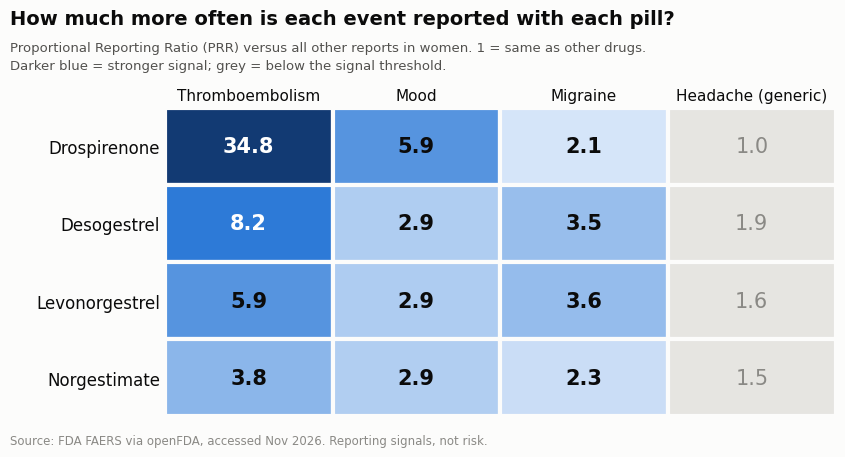

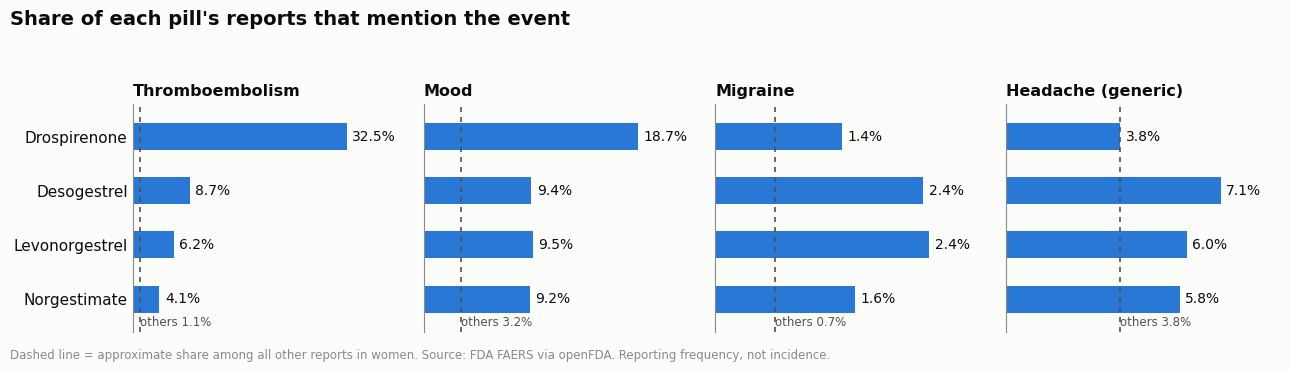

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

INK, INK2, INK3 = "#0b0b0b", "#52514e", "#8a8985"
SURFACE, BLUE, GREY = "#fcfcfb", "#2a78d6", "#e6e5e1"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.edgecolor": INK3, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
})
LABELS = {"drospirenone": "Drospirenone", "desogestrel": "Desogestrel",
          "norgestimate": "Norgestimate", "levonorgestrel_combined": "Levonorgestrel"}
EVENT_LABELS = {"thromboembolism": "Thromboembolism", "mood": "Mood",
                "migraine": "Migraine", "headache": "Headache (generic)"}
ORDER_G = ["drospirenone", "desogestrel", "levonorgestrel_combined", "norgestimate"]
ORDER_E = ["thromboembolism", "mood", "migraine", "headache"]

def heatmap(results, fname="prr_heatmap.png"):
    prr = results.pivot(index="group", columns="event", values="PRR").loc[ORDER_G, ORDER_E]
    sig = results.pivot(index="group", columns="event", values="signal").loc[ORDER_G, ORDER_E]
    cmap = LinearSegmentedColormap.from_list("blues", ["#dce9fa", BLUE, "#123a73"])
    norm = Normalize(vmin=np.log10(2), vmax=np.log10(prr.values.max()))
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    for i, g in enumerate(ORDER_G):
        for j, e in enumerate(ORDER_E):
            v, is_sig = prr.loc[g, e], bool(sig.loc[g, e])
            face = cmap(norm(np.log10(max(v, 2)))) if is_sig else GREY
            ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=face, edgecolor=SURFACE, linewidth=3))
            dark = is_sig and norm(np.log10(v)) > 0.45
            ax.text(j + .5, i + .5, f"{v:.1f}", ha="center", va="center",
                    fontsize=15, fontweight="bold" if is_sig else "normal",
                    color="white" if dark else (INK if is_sig else INK3))
    ax.set_xlim(0, len(ORDER_E)); ax.set_ylim(len(ORDER_G), 0)
    ax.set_xticks(np.arange(len(ORDER_E)) + .5)
    ax.set_xticklabels([EVENT_LABELS[e] for e in ORDER_E], fontsize=11, color=INK)
    ax.set_yticks(np.arange(len(ORDER_G)) + .5)
    ax.set_yticklabels([LABELS[g] for g in ORDER_G], fontsize=12, color=INK)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    fig.text(0.02, 0.955, "How much more often is each event reported with each pill?",
             ha="left", va="top", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.02, 0.885, "Proportional Reporting Ratio (PRR) versus all other reports in women. 1 = same as other drugs.\n"
             "Darker blue = stronger signal; grey = below the signal threshold.",
             ha="left", va="top", fontsize=9.5, color=INK2, linespacing=1.5)
    fig.text(0.02, 0.01, "Source: FDA FAERS via openFDA, accessed Nov 2026. Reporting signals, not risk.",
             fontsize=8.5, color=INK3)
    plt.subplots_adjust(top=0.74, bottom=0.07, left=0.2, right=0.98)
    fig.savefig(fname, dpi=200, facecolor=SURFACE); plt.show()

def share_bars(results, fname="share_of_reports.png"):
    df = results.copy()
    df["share"] = 100 * df["a"] / df["reports"]
    df["other"] = df["share"] / df["PRR"]
    base = df.groupby("event")["other"].median()
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
    y = np.arange(len(ORDER_G))
    for ax, e in zip(axes, ORDER_E):
        sub = df[df.event == e].set_index("group").loc[ORDER_G]
        ax.barh(y, sub["share"], height=0.5, color=BLUE)
        ax.axvline(base[e], color=INK2, linestyle=(0, (3, 3)), linewidth=1.2)
        xmax = max(sub["share"].max(), base[e]) * 1.28
        for yi, v in zip(y, sub["share"]):
            ax.text(v + xmax * .02, yi, f"{v:.1f}%", va="center", fontsize=10, color=INK)
        ax.set_xlim(0, xmax); ax.set_ylim(len(ORDER_G) - .4, -.6)
        ax.set_title(EVENT_LABELS[e], fontsize=11.5, color=INK, loc="left", fontweight="bold")
        ax.set_xticks([]); ax.tick_params(length=0)
        for s in ["top", "right", "bottom"]: ax.spines[s].set_visible(False)
        ax.text(base[e], len(ORDER_G) - .45, f"others {base[e]:.1f}%", fontsize=8.5,
                color=INK2, ha="left", va="bottom")
    axes[0].set_yticks(y); axes[0].set_yticklabels([LABELS[g] for g in ORDER_G], fontsize=11, color=INK)
    fig.suptitle("Share of each pill's reports that mention the event",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.01, 0.01, "Dashed line = approximate share among all other reports in women. "
             "Source: FDA FAERS via openFDA. Reporting frequency, not incidence.", fontsize=8.5, color=INK3)
    plt.tight_layout(rect=(0, 0.04, 1, 0.92))
    fig.savefig(fname, dpi=200, facecolor=SURFACE); plt.show()

heatmap(results)
share_bars(results)

**Reading the figures:** The figures make it clear that thromboembolism stands out, especially for drospirenone: about one in three of its reports mention a thromboembolic event. However, these figures show the frequency of the events being reported, not how often they actually happen.

## Step 8 – Age-stratified analysis

In the previous step, we compared each pill with all other reports in women. The problem is
that pill users tend to be young, whereas the other reports come from women of all ages, and
many of them are older. Age is related to most of the events we study, so it can distort the
PRR. This is called confounding.

To reduce it, we repeat the analysis within age bands, comparing each pill only with reports
from women in the same age band. We only use ages expressed in years.

First, we count the reports in each group and age band to check where there is enough data.

In [8]:
AGE_BANDS = {"10-24": (10, 24), "25-34": (25, 34), "35-44": (35, 44), "45-60": (45, 60)}

def age_query(lo, hi):
    # age in years only
    return f"patient.patientonsetageunit:801 AND patient.patientonsetage:[{lo} TO {hi}]"

rows = []
for band, (lo, hi) in AGE_BANDS.items():
    aq = age_query(lo, hi)
    row = {"age band": band, "all female reports": n(f"patient.patientsex:2 AND {aq}")}
    for g, brands in GROUPS.items():
        row[g] = n(f"{group_query(brands)} AND {aq}")
    rows.append(row)

age_counts = pd.DataFrame(rows).set_index("age band")
age_counts

,all female reports,drospirenone,desogestrel,norgestimate,levonorgestrel_combined
age band,,,,,
10-24,501759,10578,286,2307,881
25-34,600739,11340,331,2074,1090
35-44,773620,7290,225,973,810
45-60,1903559,2789,126,307,414


**Results:**
- There are about 3.78 million reports in women with an age between 10 and 60 years.
  Half of them (50%) are in the 45-60 band.
- Pill reports are concentrated in younger women: 68% of the drospirenone reports are in
  the 10-34 band, against 77% for norgestimate, 62% for levonorgestrel and 64% for
  desogestrel. For all women, this share is 29%.
- Drospirenone reports go from 10,579 (10-24) to 2,788 (45-60). Desogestrel is the
  smallest group, with 126-332 reports per band.
- The group totals are slightly lower than in Step 5 (by 5-20 reports), because we now
  exclude ages recorded in months, weeks or days.

**Takeaway:** The comparison in Step 6 was not adjusted for age. Pill reports are concentrated
in young women, while half of the comparison group is aged 45-60. Stratifying by age is
therefore the right approach. For drospirenone, norgestimate and levonorgestrel there are
enough reports in all age bands. Desogestrel has only 126-332 reports per band, so for less
frequent events, such as migraine, there will be few cases and wide confidence intervals.

Now we repeat the calculation of Step 6 within each age band.

In [9]:
import time
import requests

def n_safe(query, tries=6):
    """Like n(), but retries on rate limits (429) and server errors.
    Returns 0 only when the API says there are no matches (404)."""
    status = None
    for attempt in range(tries):
        try:
            status, total = count_reports(query)
        except requests.exceptions.RequestException:
            status = None
        if status == 200:
            return total
        if status == 404:          # NOT_FOUND = no matching reports
            return 0
        time.sleep(3 * (attempt + 1))
    raise RuntimeError(f"Request failed (status {status}) for: {query[:80]}")

rows = []
for band, (lo, hi) in AGE_BANDS.items():
    aq = age_query(lo, hi)
    N_band = n_safe(f"patient.patientsex:2 AND {aq}")           # all female reports in the band
    for ev, terms in EVENTS.items():
        eq = event_query(terms)
        ac = n_safe(f"{eq} AND patient.patientsex:2 AND {aq}")  # event reports, all drugs
        for g, brands in GROUPS.items():
            gq = f"{group_query(brands)} AND {aq}"
            ab = n_safe(gq)                                     # group reports in the band
            a = n_safe(f"{gq} AND {eq}")                        # group reports with the event
            b, c = ab - a, ac - a
            d = N_band - ab - c
            assert min(b, c, d) >= 0, f"Inconsistent counts: {band}, {ev}, {g}"
            row = {"band": band, "event": ev, "group": g, "reports": ab, "a": a}
            if min(a, b, c, d) > 0:
                prr = (a / (a + b)) / (c / (c + d))
                ror = (a * d) / (b * c)
                se = math.sqrt(1/a + 1/b + 1/c + 1/d)
                row.update({"PRR": round(prr, 2), "ROR": round(ror, 2),
                            "ROR_lo": round(math.exp(math.log(ror) - 1.96*se), 2),
                            "ROR_hi": round(math.exp(math.log(ror) + 1.96*se), 2)})
            rows.append(row)
            time.sleep(0.25)

results_age = pd.DataFrame(rows)
results_age["signal"] = (results_age["a"] >= 3) & (results_age["PRR"] >= 2) & (results_age["ROR_lo"] > 1)
print("Missing PRR values:", results_age["PRR"].isna().sum())
results_age

Missing PRR values: 1


,band,event,group,reports,a,PRR,ROR,ROR_lo,ROR_hi,signal
0,10-24,thromboembolism,drospirenone,10578,3188,45.62,64.87,61.46,68.47,True
1,10-24,thromboembolism,desogestrel,286,33,9.04,10.09,7.01,14.51,True
2,10-24,thromboembolism,norgestimate,2307,127,4.36,4.56,3.80,5.46,True
3,10-24,thromboembolism,levonorgestrel_combined,881,61,5.44,5.77,4.45,7.50,True
4,10-24,mood,drospirenone,10578,2214,5.00,6.06,5.77,6.37,True
...,...,...,...,...,...,...,...,...,...,...
59,45-60,migraine,levonorgestrel_combined,414,9,2.35,2.38,1.23,4.60,True
60,45-60,headache,drospirenone,2789,113,0.78,0.77,0.64,0.93,False
61,45-60,headache,desogestrel,126,7,1.07,1.08,0.50,2.31,False
62,45-60,headache,norgestimate,307,25,1.57,1.62,1.08,2.44,False


In [10]:
order_g = ["drospirenone", "desogestrel", "levonorgestrel_combined", "norgestimate"]
order_e = ["thromboembolism", "mood", "migraine", "headache"]
idx = pd.MultiIndex.from_product([order_e, order_g])

prr_by_age = results_age.pivot(index=["event", "group"], columns="band", values="PRR")
cases_by_age = results_age.pivot(index=["event", "group"], columns="band", values="a")

print("PRR by age band")
display(prr_by_age.reindex(idx)[list(AGE_BANDS)])
print("\nNumber of reports with the event (a)")
display(cases_by_age.reindex(idx)[list(AGE_BANDS)])

PRR by age band


band                                     10-24  25-34  35-44  45-60
thromboembolism drospirenone             45.62  40.16  52.83  59.75
                desogestrel               9.04   6.58   7.64  12.96
                levonorgestrel_combined   5.44   4.53   5.85   9.29
                norgestimate              4.36   3.56   4.05   6.88
mood            drospirenone              5.00   4.54   4.32   5.28
                desogestrel               2.55   1.79   1.77   1.69
                levonorgestrel_combined   2.46   2.22   1.72   1.41
                norgestimate              2.20   1.95   1.82   1.82
migraine        drospirenone              1.99   1.34   1.00   1.01
                desogestrel               2.37   1.45   3.34    NaN
                levonorgestrel_combined   2.78   2.06   2.11   2.35
                norgestimate              2.01   1.63   0.98   1.76
headache        drospirenone              1.06   0.83   0.80   0.78
                desogestrel               2.50   1.38   0.96   1.07
                levonorgestrel_combined   1.53   1.40   1.43   1.40
                norgestimate              1.55   1.46   1.43   1.57


Number of reports with the event (a)


band                                     10-24  25-34  35-44  45-60
thromboembolism drospirenone              3188   4220   3621   1599
                desogestrel                 33     35     24     17
                levonorgestrel_combined     61     79     66     40
                norgestimate               127    118     55     22
mood            drospirenone              2214   2522   1537    550
                desogestrel                 33     31     20      8
                levonorgestrel_combined     98    126     70     22
                norgestimate               229    211     89     21
migraine        drospirenone               152    188    107     26
                desogestrel                  5      6     11      0
                levonorgestrel_combined     18     28     25      9
                norgestimate                34     42     14      5
headache        drospirenone               425    433    323    113
                desogestrel                 27     21     12      7
                levonorgestrel_combined     51     70     64     30
                norgestimate               135    139     77     25

**Results:**
- **Thromboembolism:** it is a signal in every age band and for all four pills. Drospirenone
  has a PRR between 40 and 60, and the share of its reports mentioning thromboembolism rises
  from 30% to 57% with age. For the other pills the PRR is between 3.6 and 13.0.
- **Mood:** drospirenone remains a signal in every age band (PRR 4.3-5.3). The other three
  pills drop from about 2.9 to 1.4-2.6, and they exceed 2 only in the younger age bands.
- **Migraine:** drospirenone is not a signal in any age band (PRR from 1.99 to 1.00).
  Levonorgestrel is a signal in every age band (PRR 2.06-2.78), but with only 9-28 cases.
  Desogestrel and norgestimate show only isolated signals with few cases. Desogestrel has no
  migraine reports at 45-60 years, so its PRR cannot be calculated.
- **Headache:** there is only one signal out of 16 (desogestrel, 10-24 years). For
  drospirenone, the PRR is below 1 from age 25 onwards (0.78-0.83).


**Takeaway:** The thromboembolism signal is not explained by age: for drospirenone, the PRR is even higher within age bands (40–60) than overall (34.8). The mood signal weakens for the other three pills, but it remains strong for drospirenone, which may again reflect litigation-driven reporting. The migraine signal of drospirenone seen in Step 6 disappears, which is compatible with an effect of age. Generic headache, our comparison event, gives only one signal out of 16. Uncertainty remains for small groups, especially desogestrel.

The figure shows how the PRR changes with age. Each panel is an event and each line is a pill.
A filled dot means a signal, an empty dot means no signal. The dashed line is the threshold
PRR = 2. The vertical axis is logarithmic because the PRR ranges from about 1 to 60.

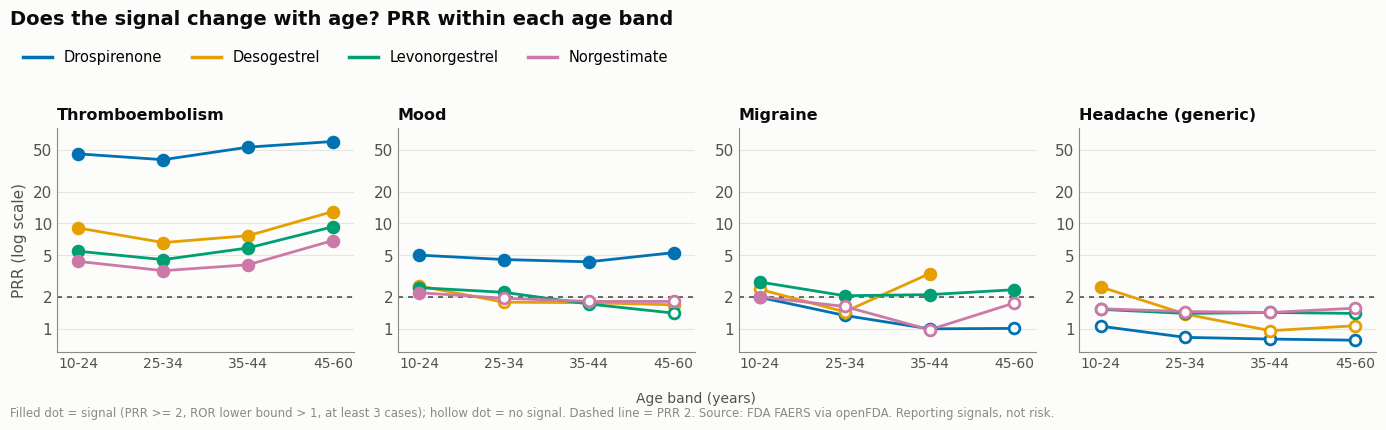

In [11]:
from matplotlib.lines import Line2D
from matplotlib.ticker import NullLocator

COLORS = {"drospirenone": "#0072B2", "desogestrel": "#E69F00",
          "levonorgestrel_combined": "#009E73", "norgestimate": "#CC79A7"}
BANDS = list(AGE_BANDS)

def age_lines(results_age, fname="prr_by_age.png"):
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.2), sharex=True)
    x = np.arange(len(BANDS))
    for ax, e in zip(axes, ORDER_E):
        for g in ORDER_G:
            sub = (results_age[(results_age.event == e) & (results_age.group == g)]
                   .set_index("band").loc[BANDS])
            ax.plot(x, sub["PRR"], color=COLORS[g], linewidth=2, zorder=2)
            for xi, prr, sig in zip(x, sub["PRR"], sub["signal"]):
                if np.isnan(prr):
                    continue
                ax.scatter(xi, prr, s=60, zorder=3, edgecolor=COLORS[g], linewidth=2,
                           facecolor=COLORS[g] if sig else SURFACE)
        ax.axhline(2, color=INK2, linestyle=(0, (3, 3)), linewidth=1.2, zorder=1)
        ax.set_yscale("log"); ax.set_ylim(0.6, 80)
        ax.set_yticks([1, 2, 5, 10, 20, 50]); ax.set_yticklabels(["1", "2", "5", "10", "20", "50"])
        ax.yaxis.set_minor_locator(NullLocator())
        ax.grid(axis="y", color=GREY, linewidth=0.8); ax.set_axisbelow(True)
        ax.set_xticks(x); ax.set_xticklabels(BANDS, fontsize=10)
        ax.set_xlim(-0.25, len(BANDS) - 0.75)
        ax.set_title(EVENT_LABELS[e], fontsize=11.5, color=INK, loc="left", fontweight="bold")
        ax.tick_params(length=0)
        for s in ["top", "right"]: ax.spines[s].set_visible(False)
    axes[0].set_ylabel("PRR (log scale)")
    handles = [Line2D([0], [0], color=COLORS[g], linewidth=2.5, label=LABELS[g]) for g in ORDER_G]
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.01, 0.915),
               ncol=4, frameon=False, fontsize=10.5)
    fig.suptitle("Does the signal change with age? PRR within each age band",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.5, 0.045, "Age band (years)", ha="center", fontsize=10, color=INK2)
    fig.text(0.01, 0.01, "Filled dot = signal (PRR >= 2, ROR lower bound > 1, at least 3 cases); "
             "hollow dot = no signal. Dashed line = PRR 2. Source: FDA FAERS via openFDA. Reporting signals, not risk.",
             fontsize=8.5, color=INK3)
    plt.tight_layout(rect=(0, 0.08, 1, 0.87))
    fig.savefig(fname, dpi=200, facecolor=SURFACE); plt.show()

age_lines(results_age)

**Reading the figure:**
- **Thromboembolism:** the lines stay high and almost flat. Drospirenone is much higher than
  the other pills (PRR 40-60), and all the dots are filled, so the signal does not depend on age.
- **Mood:** drospirenone stays around 5, whereas the other three pills fall close to or below
  the threshold as age increases.
- **Migraine:** drospirenone falls to about 1, but levonorgestrel stays above 2 in every age
  band, with few cases.
- **Headache:** almost all the dots are below the threshold, and the only filled dot is
  desogestrel at 10-24 years.
- As always, the figure shows how often an event is reported, not the risk.

## Step 9 - Reporting over time
Several of our takeaways suggest that the lawsuits against Yaz and Yasmin could have inflated the number of reports. To test this hypothesis, we count the reports and the share of reports mentioning thromboembolism year by year. If our concern is correct, there will be a peak of reports in a few years, with a higher share of thromboembolism exactly during those years.

In [12]:
YEARS = range(2004, 2026)
THROMBO_Q = event_query(EVENTS["thromboembolism"])

def year_query(y):
    return f"receivedate:[{y}0101 TO {y}1231]"   # date the FDA received the report

rows = []
for y in YEARS:
    yq = year_query(y)
    all_w = n_safe(f"patient.patientsex:2 AND {yq}")                 # all reports in women
    all_t = n_safe(f"patient.patientsex:2 AND {THROMBO_Q} AND {yq}")  # ... with thromboembolism
    for g, brands in GROUPS.items():
        gq = f"{group_query(brands)} AND {yq}"
        rows.append({"year": y, "group": g,
                     "reports": n_safe(gq),
                     "thrombo": n_safe(f"{gq} AND {THROMBO_Q}"),
                     "all_women": all_w, "all_women_thrombo": all_t})
        time.sleep(0.25)
    print(y, "done")

by_year = pd.DataFrame(rows)
by_year["share_thrombo"] = 100 * by_year["thrombo"] / by_year["reports"]
by_year["share_all"] = 100 * by_year["all_women_thrombo"] / by_year["all_women"]

print("Reports per year")
display(by_year.pivot(index="year", columns="group", values="reports")[ORDER_G])
print("\nShare of reports mentioning thromboembolism (%)")
display(by_year.pivot(index="year", columns="group", values="share_thrombo")[ORDER_G].round(1))

2004 done
2005 done
2006 done
2007 done
2008 done
2009 done
2010 done
2011 done
2012 done
2013 done
2014 done
2015 done
2016 done
2017 done
2018 done
2019 done
2020 done
2021 done
2022 done
2023 done
2024 done
2025 done
Reports per year


group,drospirenone,desogestrel,levonorgestrel_combined,norgestimate
year,,,,
2004,199,40,152,552
2005,286,51,127,266
2006,340,64,107,242
2007,533,56,104,268
2008,3877,34,172,154
2009,3013,39,149,193
2010,2590,33,196,275
2011,11173,94,325,467
2012,9977,93,357,490



Share of reports mentioning thromboembolism (%)


group,drospirenone,desogestrel,levonorgestrel_combined,norgestimate
year,,,,
2004,18.6,12.5,7.2,2.4
2005,19.9,19.6,7.9,7.1
2006,13.5,7.8,7.5,6.6
2007,17.8,17.9,20.2,5.6
2008,4.3,20.6,12.8,5.2
2009,9.9,17.9,6.7,9.3
2010,23.4,18.2,11.7,12.7
2011,27.7,11.7,11.4,12.2
2012,50.8,24.7,10.4,14.9


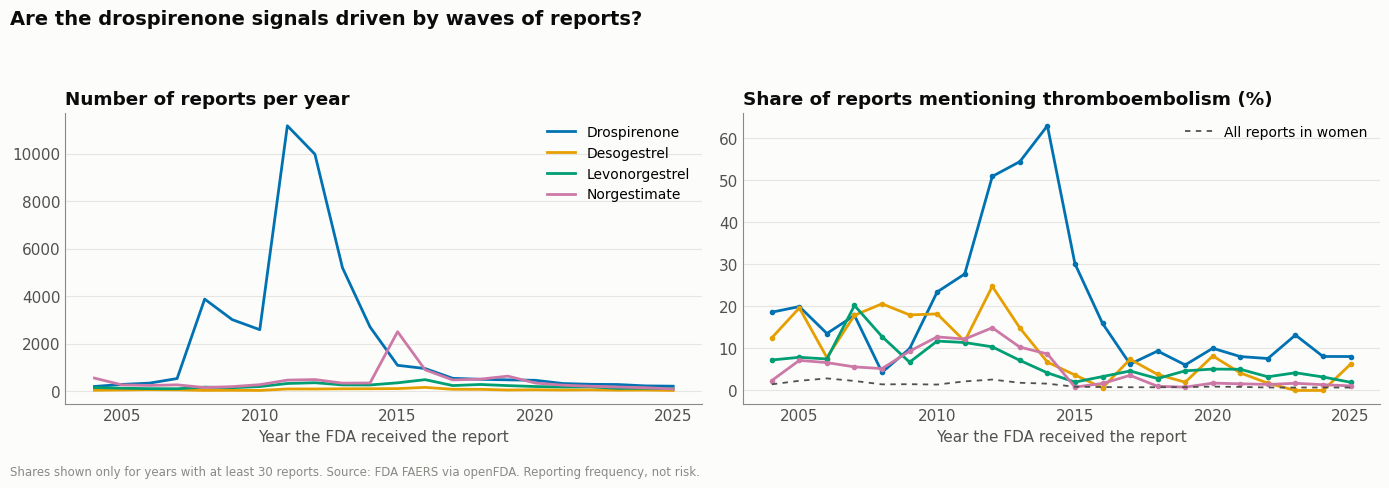

In [13]:
def year_plot(by_year, fname="reports_by_year.png", min_reports=30):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    for g in ORDER_G:
        sub = by_year[by_year.group == g].set_index("year")
        axes[0].plot(sub.index, sub["reports"], color=COLORS[g], linewidth=2, label=LABELS[g])
        # hide years with too few reports: the share would be unstable
        share = sub["share_thrombo"].where(sub["reports"] >= min_reports)
        axes[1].plot(sub.index, share, color=COLORS[g], linewidth=2, marker="o", markersize=3)
    base = by_year.drop_duplicates("year").set_index("year")["share_all"]
    axes[1].plot(base.index, base, color=INK2, linestyle=(0, (3, 3)), linewidth=1.3,
                 label="All reports in women")

    axes[0].set_title("Number of reports per year", loc="left", fontweight="bold", color=INK)
    axes[1].set_title("Share of reports mentioning thromboembolism (%)", loc="left",
                      fontweight="bold", color=INK)
    for ax in axes:
        ax.grid(axis="y", color=GREY, linewidth=0.8); ax.set_axisbelow(True)
        ax.tick_params(length=0)
        for s in ["top", "right"]: ax.spines[s].set_visible(False)
        ax.set_xlabel("Year the FDA received the report", color=INK2)
    axes[0].legend(frameon=False, fontsize=10)
    axes[1].legend(frameon=False, fontsize=10, loc="upper right")
    fig.suptitle("Are the drospirenone signals driven by waves of reports?",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
    fig.text(0.01, 0.01, f"Shares shown only for years with at least {min_reports} reports. "
             "Source: FDA FAERS via openFDA. Reporting frequency, not risk.", fontsize=8.5, color=INK3)
    plt.tight_layout(rect=(0, 0.04, 1, 0.92))
    fig.savefig(fname, dpi=200, facecolor=SURFACE); plt.show()

year_plot(by_year)

**Results:**
- Drospirenone reports show a large wave: from a few hundred to 11,173 in 2011 and 9,977 in 2012. About 85% of all drospirenone reports were received between 2008 and 2014.
- For drospirenone, the share of reports mentioning thromboembolism rises from an initial 13-20% to 51-63% in 2012-2014, and goes back to 6-13% after 2016. For all women it stays at 1-3%.
- Other pills do not have a similar wave. The peak of norgestimate in 2015 does not concern thromboembolism (0.8%).

**Takeaway:** The timing supports our hypothesis: the peak of reports regarding drospirenone and the peak of the share of reports mentioning thromboembolism overlap, as we would expect from reports influenced by lawsuits. This does not mean the signal from drospirenone is fake. Even after the wave (6-13%), it stays higher than for the other pills and for all reports in women (1-3%). The lawsuits inflated the signal, but they did not create it. The PRR values of Steps 6 and 8 (34.8 and 40-60 within age bands) overstate the size of the signal, so they must be read with caution.



## Limitations

**Data**
- FAERS contains only spontaneous reports, so we do not know how many women actually take each pill. Therefore, we cannot calculate the risk, only compare how often an event is reported.
- The same case can be reported several times, and we cannot remove these duplicates.
- Age (in years) is available for only about a third of the reports on women.

**Groups**
- The groups are based on a list of brand names written by the reporter, so some products may be missed.
- A report can mention more than one pill, so it can appear in more than one group.

**Methods**
- We stratified by age, but we did not adjust for other variables such as smoking, obesity or other drugs. Each patient has different lifestyle and health conditions.
- The database changes over time, so running the notebook again can give slightly different numbers.

## Conclusions
We asked whether pills with different progestins had different profiles of reported events. Thromboembolism shows a signal for all pills, not explained by age. For drospirenone the signal is inflated by the lawsuits but it stays.
For three pills, the mood signal weakens within age bands; for drospirenone it stays.
Migraine has weak signals. The drospirenone signal disappears when we account for age. The limits of the project are that the reports are spontaneous, that the groups are defined by brand name and that duplicates were not removed.

These are signals that need to be investigated further, not proof. Anyone who takes the pill should discuss any concerns with their doctor.